# Supplementary Figure S5d. Genome-wide fine-mapping versus hit-based fine-mapping and marginal testing

Left: S-LDSC heritability enrichment (top) and marginal τ* (bottom) of three TransMap-eGene-style annotations: genome-wide fine-mapping (95% CS PIPs of SuSiE credible sets with lead p < 1e-5; TransMap-eGene), "hit-based" fine-mapping (the subset of the same genome-wide credible sets whose lead variant reaches p < 5e-8; it is not a separate fine-mapping run seeded on hits), and marginal association (binary annotation of variants with marginal trans p < 1e-5). Source: `Manu_Figures/Figure2.ipynb` cells 44-45 (input `trans_single/results/sLDSC_Finemapping_Marginal_Figure2a.rds`), bars with a dashed line at 0.

Error bars are estimate ± 1.9 × SE, exactly as in the source figure code (Figure2.ipynb uses 1.9, not 1.96; the caption's "95% confidence intervals" would be ± 1.96 × SE). Red asterisks mark nominal two-sided P < 0.05 with a positive estimate, again as in the source code; no multiple-testing correction is applied, although the caption says "FDR<5%". For reference the rds also has `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in this panel (not used for the stars). S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs; they match the summary rds read by the source notebook to machine precision. Enrichment P-values come from the h2-scaled enrichment statistic (author's `runSingleEnrMetaAnalysis`); the plotted estimate/SE is the meta-analysed S-LDSC Enrichment.

Note that the star rule tests est > 0, not est > 1: the marginal-association enrichment (≈0.94, i.e. a depletion) still receives an asterisk because its P-value is < 0.05.

Right: number of unique variants per expression context in the genome-wide fine-mapping 95% CS (x) versus the hit-based set (squares) or marginally significant variants (triangles) (y), log10 axes; dashed red line is y = x. Counts come from `Figure2.ipynb` cell 30 and were saved by cell 33 as `figures/Figure2_Final/FigureS4d_fm_vs_hits_context_scatter_source_data.tsv` (values identical to the cell 34 printout: e.g. Mic 374,894 / 22,882 / 3,422,810).

Input: `data/Figure_S5d_finemapping_vs_hits.rds` (list: `sldsc`, `trans_eqtl_counts`).

In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S5d_finemapping_vs_hits.rds")
d$sldsc
d$trans_eqtl_counts

metric,trait_set,trait,method,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),Genome-wide fine-mapping (TransMap-eGene),Trans_Single,2.74789358,0.126340058,2.873073e-19,2.585766e-18,57
Enrichment,blood_traits,Blood-related traits (22),Genome-wide fine-mapping (TransMap-eGene),Trans_Single,2.19917492,0.202188802,1.436264e-04,1.846626e-04,22
Enrichment,brain_traits,Brain-related traits (18),Genome-wide fine-mapping (TransMap-eGene),Trans_Single,3.43560995,0.168625531,4.182436e-11,1.882096e-10,18
Enrichment,all_traits,All traits (57),Hit-based fine-mapping,Trans_Single_pv5e8,4.10301962,0.501153969,2.376695e-06,3.565043e-06,57
Enrichment,blood_traits,Blood-related traits (22),Hit-based fine-mapping,Trans_Single_pv5e8,1.95639877,0.965638383,9.267339e-01,9.267339e-01,22
Enrichment,brain_traits,Brain-related traits (18),Hit-based fine-mapping,Trans_Single_pv5e8,6.61463096,0.889091169,3.071880e-08,8.143975e-08,18
Enrichment,all_traits,All traits (57),Marginal association,Marignal_eQTL_pv1e5,0.93571578,0.010875678,2.031086e-07,3.655955e-07,57
Enrichment,blood_traits,Blood-related traits (22),Marginal association,Marignal_eQTL_pv1e5,0.93242361,0.018712728,5.665058e-03,6.373190e-03,22
Enrichment,brain_traits,Brain-related traits (18),Marginal association,Marignal_eQTL_pv1e5,0.88620261,0.017333953,3.619544e-08,8.143975e-08,18


context,context_label,fm_variants,comparison,comparison_variants
<chr>,<chr>,<dbl>,<chr>,<dbl>
Mic,Microglia,374894,Hit-based fine-mapping,22882
Mic,Microglia,374894,Marginal significant,3422810
Exc,Excitatory Neurons,301366,Hit-based fine-mapping,23253
Exc,Excitatory Neurons,301366,Marginal significant,3242600
Inh,Inhibitory Neurons,442569,Hit-based fine-mapping,28617
Inh,Inhibitory Neurons,442569,Marginal significant,3404070
Ast,Astrocytes,494240,Hit-based fine-mapping,32587
Ast,Astrocytes,494240,Marginal significant,3455131
Oli,Oligodendrocytes,463780,Hit-based fine-mapping,33852


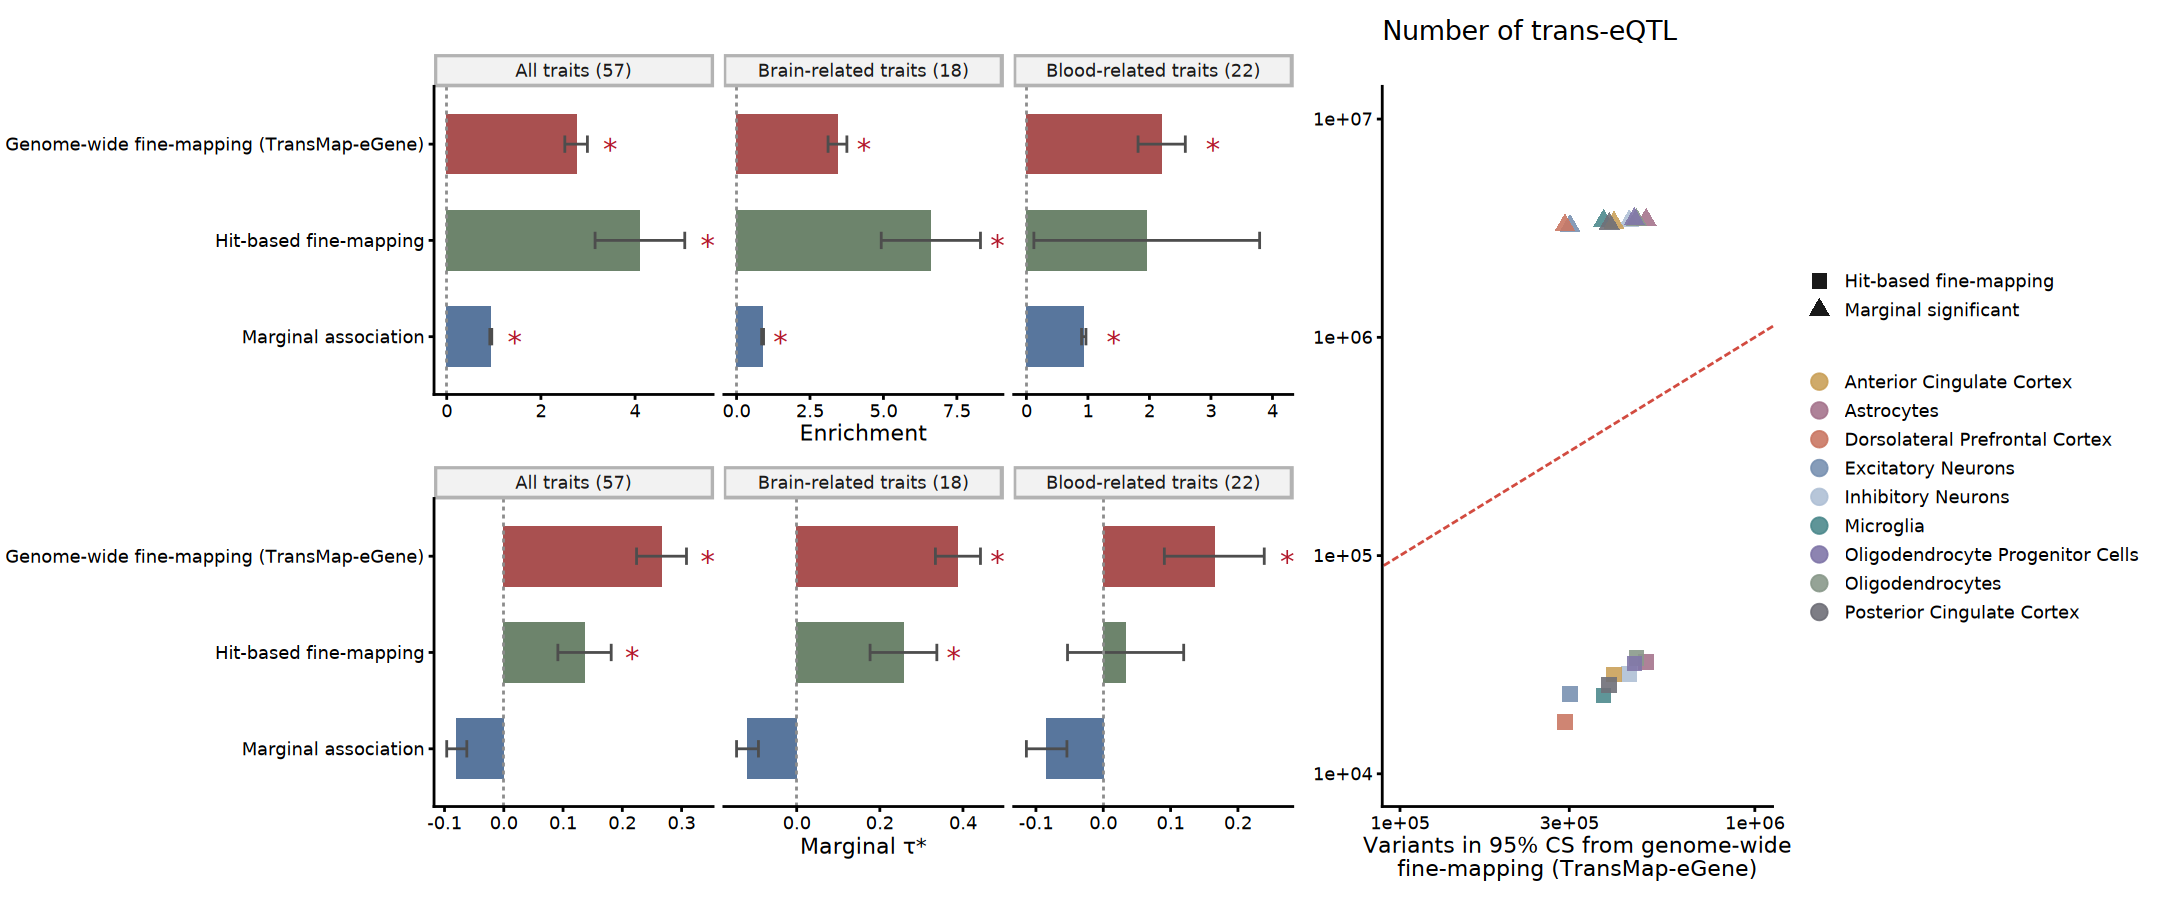

In [2]:
cols <- c("#A95050", "#6D846C", "#58769D")
res <- d$sldsc
names(cols) <- levels(res$method)
res$method <- factor(res$method, levels = rev(levels(res$method)))
res$star <- ifelse(res$pvalue < 0.05 & res$est > 0, "*", "")
bars <- function(m, xl) {
  r <- subset(res, metric == m)
  pad <- 0.04 * diff(range(c(r$est - 1.9 * r$se, r$est + 1.9 * r$se, 0)))
  ggplot(r, aes(x = est, y = method, fill = method)) +
    geom_col(width = 0.62) +
    geom_errorbar(aes(xmin = est - 1.9 * se, xmax = est + 1.9 * se), orientation = "y", width = 0.18, colour = "grey30") +
    geom_text(aes(x = est + 1.9 * se + pad, label = star), colour = "#B2182B", size = 6, hjust = 0, vjust = 0.7) +
    geom_vline(xintercept = 0, linetype = "dashed", colour = "grey55") +
    facet_grid(. ~ trait, scales = "free_x") +
    scale_fill_manual(values = cols, guide = "none") +
    labs(x = xl, y = NULL) +
    theme_classic(base_size = 13) + theme(strip.background = element_rect(fill = "grey95", colour = "grey70"))
}
left <- bars("Enrichment", "Enrichment") / bars("Marginal tau*", expression("Marginal " * tau * "*"))

ctx_cols <- c("Excitatory Neurons" = "#7991B1", "Inhibitory Neurons" = "#AFC0D5", "Microglia" = "#4E8A8D",
              "Astrocytes" = "#A5748D", "Oligodendrocytes" = "#89998B", "Oligodendrocyte Progenitor Cells" = "#8177A8",
              "Anterior Cingulate Cortex" = "#C9A15A", "Dorsolateral Prefrontal Cortex" = "#C97864",
              "Posterior Cingulate Cortex" = "#6F6F78")
cnt <- d$trans_eqtl_counts
right <- ggplot(cnt, aes(x = fm_variants, y = comparison_variants)) +
  geom_abline(slope = 1, intercept = 0, linetype = "longdash", colour = "#D24B40") +
  geom_point(aes(colour = context_label, shape = comparison), size = 4, alpha = 0.9) +
  scale_colour_manual(values = ctx_cols, name = NULL) +
  scale_shape_manual(values = c("Hit-based fine-mapping" = 15, "Marginal significant" = 17), name = NULL) +
  scale_x_log10(limits = c(1e5, 1e6)) + scale_y_log10(limits = c(1e4, 1e7)) +
  labs(x = "Variants in 95% CS from genome-wide\nfine-mapping (TransMap-eGene)", y = NULL,
       title = "Number of trans-eQTL") +
  theme_classic(base_size = 13)
options(repr.plot.width = 18, repr.plot.height = 7.5)
(left | right) + plot_layout(widths = c(2.2, 1))